In [1]:
import scanpy as sc
import pandas as pd

import sys, os

import matplotlib.pyplot as plt
import palettable

from scipy.sparse import issparse
import numpy as np

from pathlib import Path
_p = Path(".").resolve()
while not (_p / "src" / "config.py").exists() and _p != _p.parent:
    _p = _p.parent
sys.path.insert(0, str(_p))
from src.config import ANALYSIS_DIR, DATA_DIR, PROJECT_ROOT


In [2]:
import os, sys


In [3]:

d10_lapa_dz_clustered = sc.read_h5ad(ANALYSIS_DIR / "data-objects/cellassign/d10_lapa_predictions.h5ad")

#### Print the metadata we filter one

In [4]:
d10_lapa_dz_clustered.obs

,orig.ident,nCount_RNA,nFeature_RNA,freemuxlet.identity,participant,Condition,Time_point,Treatment,ident,leiden,size_factor,initial_cellassign_prediction
AAACCAAAGGGTATGG-1,D10_Lapa,8249.0,3045,0,H896,G2D10_Lapa,G2D10,Lapa,D10_Lapa,2,0.889328,ISCs
AAACCAAAGGTTCAGC-1,D10_Lapa,5951.0,2426,0,H896,G2D10_Lapa,G2D10,Lapa,D10_Lapa,2,0.641580,ISCs
AAACCAAAGTAATGGA-1,D10_Lapa,6314.0,2901,1,H897,G2D10_Lapa,G2D10,Lapa,D10_Lapa,2,0.680715,ISCs
AAACCAAAGTCAGCAC-1,D10_Lapa,13571.0,4660,0,H896,G2D10_Lapa,G2D10,Lapa,D10_Lapa,6,1.463095,ISCs
AAACCAAAGTGCGCTG-1,D10_Lapa,5743.0,2694,0,H896,G2D10_Lapa,G2D10,Lapa,D10_Lapa,0,0.619155,ISCs
...,...,...,...,...,...,...,...,...,...,...,...,...
TGTGTTGAGGCGCTCA-1,D10_Lapa,7927.0,3290,0,H896,G2D10_Lapa,G2D10,Lapa,D10_Lapa,0,0.854613,ISCs
TGTGTTGAGGGTGAAT-1,D10_Lapa,12886.0,4452,2,H329,G2D10_Lapa,G2D10,Lapa,D10_Lapa,4,1.389245,Proliferating PCs
TGTGTTGAGTAGAGCG-1,D10_Lapa,6993.0,3144,0,H896,G2D10_Lapa,G2D10,Lapa,D10_Lapa,1,0.753918,ISCs
TGTGTTGAGTAGCGTC-1,D10_Lapa,6865.0,2951,2,H329,G2D10_Lapa,G2D10,Lapa,D10_Lapa,2,0.740119,ISCs


In [5]:
print(d10_lapa_dz_clustered.obs['initial_cellassign_prediction'])

AAACCAAAGGGTATGG-1                 ISCs
AAACCAAAGGTTCAGC-1                 ISCs
AAACCAAAGTAATGGA-1                 ISCs
AAACCAAAGTCAGCAC-1                 ISCs
AAACCAAAGTGCGCTG-1                 ISCs
                            ...        
TGTGTTGAGGCGCTCA-1                 ISCs
TGTGTTGAGGGTGAAT-1    Proliferating PCs
TGTGTTGAGTAGAGCG-1                 ISCs
TGTGTTGAGTAGCGTC-1                 ISCs
TGTGTTGAGTCGCGCA-1                 ISCs
Name: initial_cellassign_prediction, Length: 33507, dtype: category
Categories (7, object): ['EECs', 'Enterocytes', 'Goblet cells', 'ISCs', 'PCs', 'Proliferating PCs', 'Secretory PCs']


### Create a new object for our EEC cells

In [6]:
label_to_keep = ["EECs"]            # or ["3","7","9"]
metadata_key = "initial_cellassign_prediction"

mask = d10_lapa_dz_clustered.obs[metadata_key].isin(label_to_keep)
EECs_only = d10_lapa_dz_clustered[mask].copy() 

In [7]:
EECs_only

AnnData object with n_obs × n_vars = 819 × 28395
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden', 'size_factor', 'initial_cellassign_prediction'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'X_name', 'hvg', 'initial_cellassign_prediction_colors', 'leiden_colors'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

/opt/anaconda3/envs/single-cell-env/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:82: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return fn(*args_all, **kw)
/opt/anaconda3/envs/single-cell-env/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/anaconda3/envs/single-cell-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/gs/k55rgtm50g938k87mvcdclqr0000gq/T/ipykernel_17068/2911989776.py:21: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc

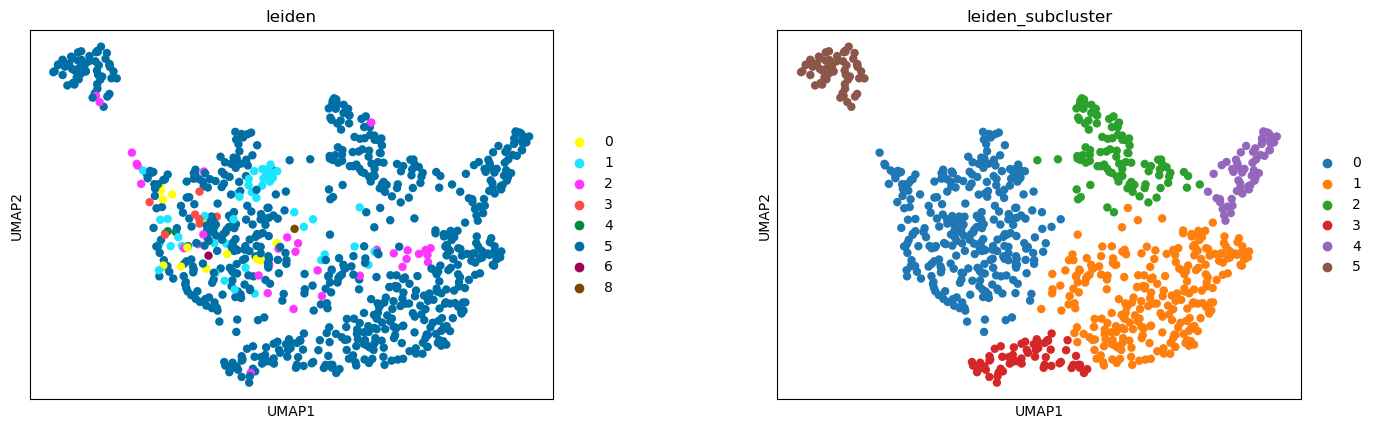

In [8]:
### Recluster

if "counts" in EECs_only.layers:
    EECs_only.X = EECs_only.layers["counts"].copy()
    sc.pp.filter_genes(EECs_only, min_counts=1)
    sc.pp.normalize_total(EECs_only, target_sum=1e4)
    sc.pp.log1p(EECs_only)

# Standard preprocessing
sc.pp.highly_variable_genes(EECs_only, n_top_genes=3000, flavor="seurat_v3")
adata_sub = EECs_only[:, EECs_only.var["highly_variable"]].copy()

sc.pp.scale(adata_sub, max_value=10)
sc.tl.pca(adata_sub, n_comps=50, svd_solver="arpack")

# Graph + UMAP
sc.pp.neighbors(adata_sub, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_sub)

# --- Recluster and save to a NEW slot ---
sc.tl.leiden(
    adata_sub,
    resolution=0.3,
    key_added="leiden_subcluster"   # <- new column in .obs
)

# (Nice-to-have) ensure string/categorical with clean ordering
adata_sub.obs["leiden_subcluster"] = (
    adata_sub.obs["leiden_subcluster"].astype(str).astype("category")
)

# Quick check
sc.pl.umap(adata_sub, color=["leiden", "leiden_subcluster"], wspace=0.3)

In [9]:
adata = adata_sub

#### Define the EEC hormones, for plotting

In [10]:
Enterochromaffin_markers = ["CHGA", "TPH1", "NEUROD1"]

Peptide_cell_markers = ["ARX", "MLN", "GHRL", "GIP", "CCK"]



EEC_marker_dictionary = {
    "Enterochromaffin_markers": ["CHGA", "TPH1", "NEUROD1"],
    "Peptide_cell_marker": ["ARX"],
    "M_cell_marker": ["MLN"],
    "X_cell_marker": ["GHRL"],
    "K_cell_marker": ["GIP"],
    "I_cell_marker": ["CCK"]

### TO DO; consider adding 'more' genes to this
}


#### Plot Enterochromaffin markers

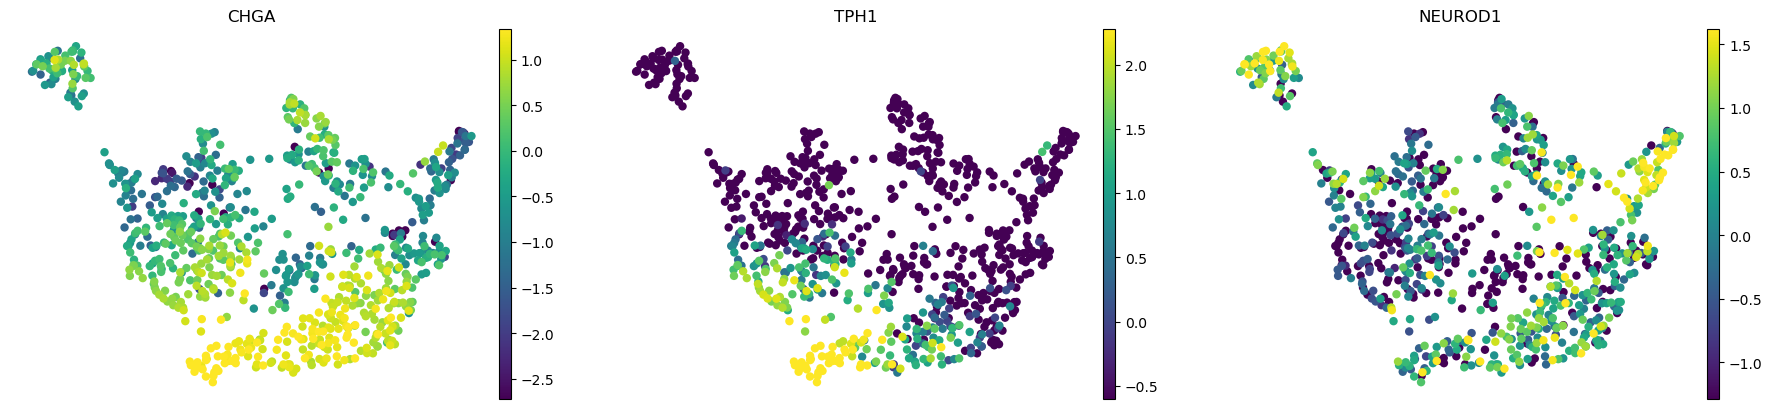

In [11]:
present = [g for g in Enterochromaffin_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

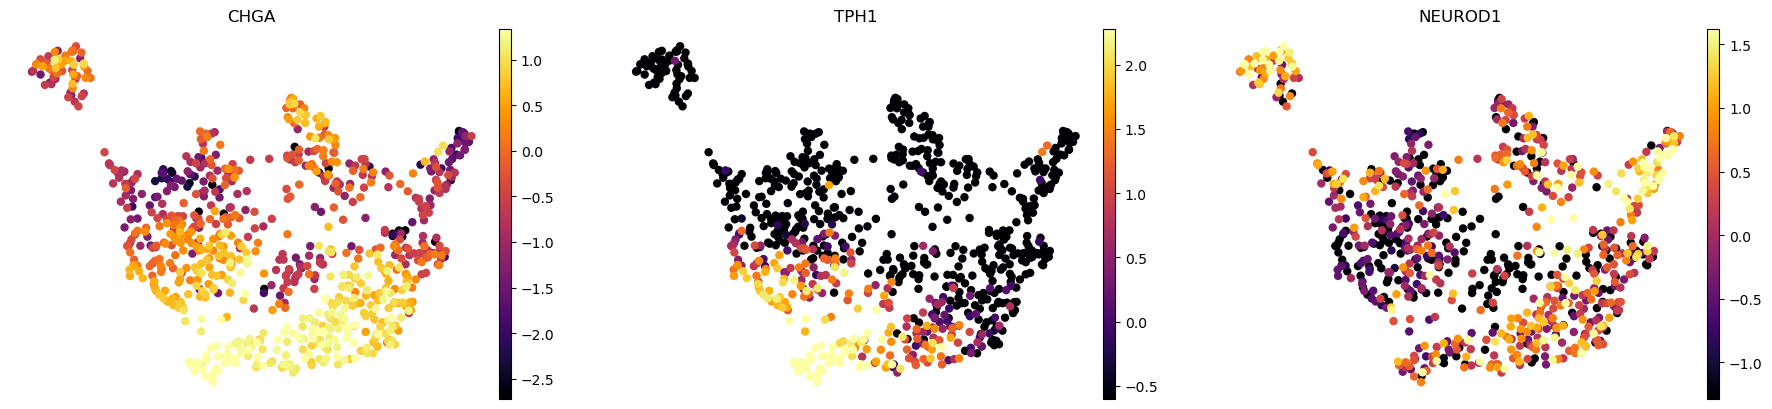

In [12]:
sc.pl.umap(
    adata,
    color=present,
    ncols=4,   
    cmap="inferno",# show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)





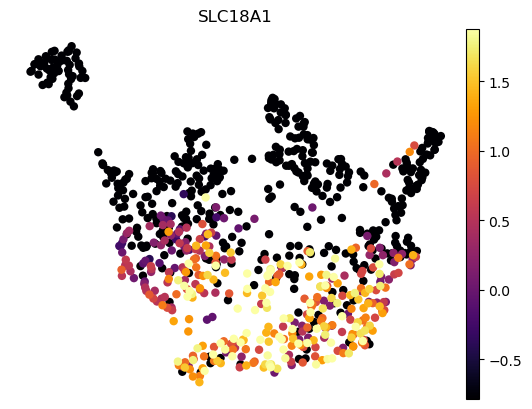

In [13]:
sc.pl.umap(
    adata,
    color="SLC18A1",
    ncols=4,   
    cmap="inferno",# show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)





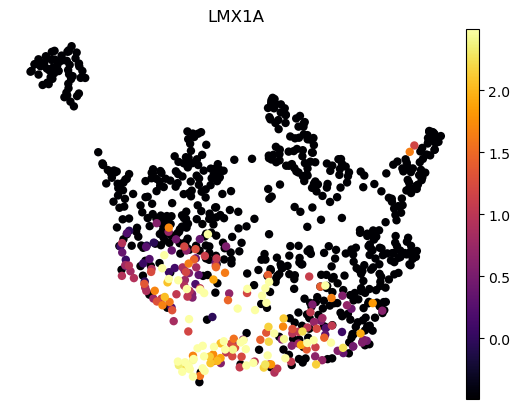

In [14]:
sc.pl.umap(
    adata,
    color="LMX1A",
    ncols=4,   
    cmap="inferno",# show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)




#### Plot NEUROG3+ 

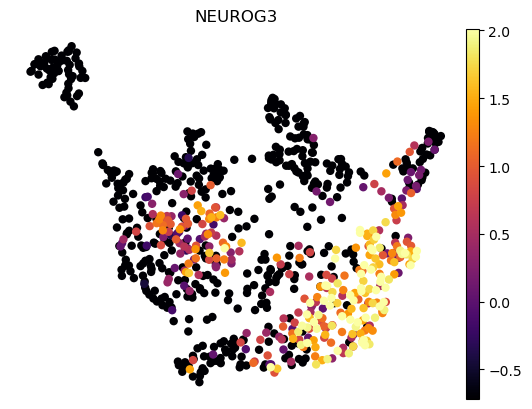

In [15]:
sc.pl.umap(
    adata,
    color="NEUROG3",
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95", 
    cmap="inferno",         
    frameon=False
)

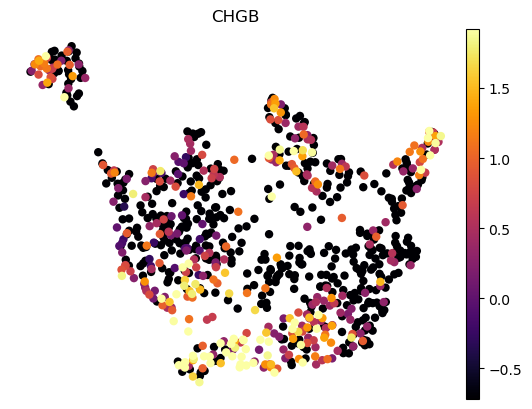

In [16]:
sc.pl.umap(
    adata,
    color="CHGB",
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95", 
    cmap="inferno",         
    frameon=False
)

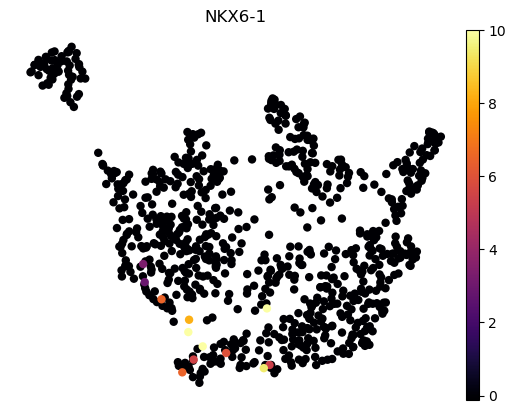

In [17]:
sc.pl.umap(
    adata,
    color="NKX6-1",
    ncols=4,          # show expression from .raw if you froze it
    cmap="inferno",         
    frameon=False
)

#### Plot peptide hormone markers

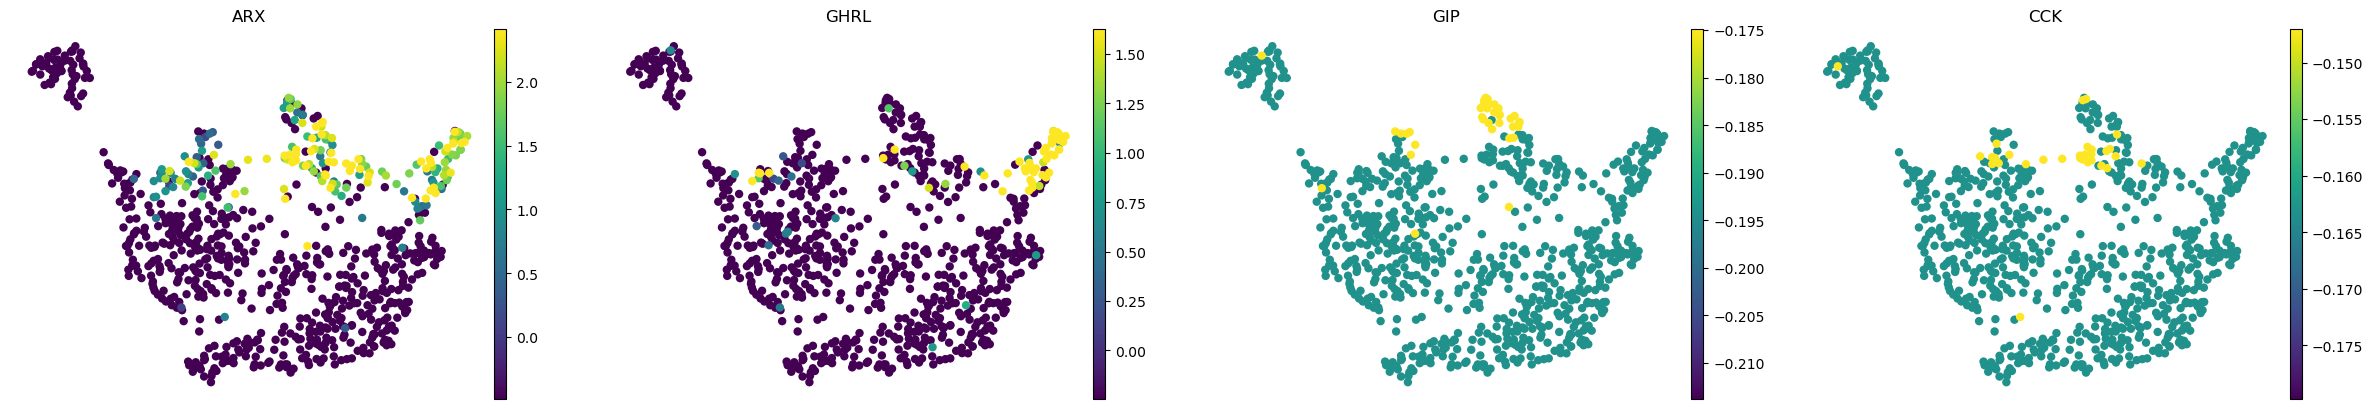

In [18]:
present = [g for g in Peptide_cell_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

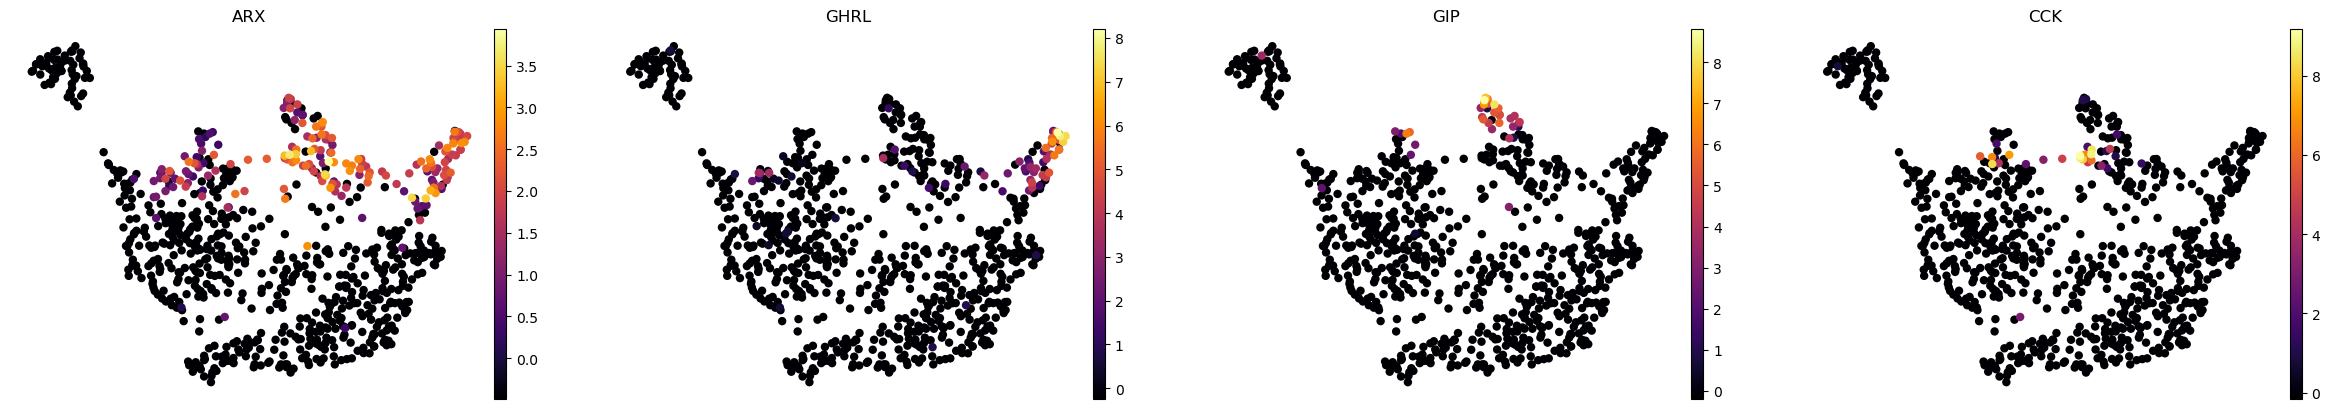

In [19]:
present = [g for g in Peptide_cell_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4, 
    cmap="inferno",         # show expression from .raw if you froze it
    frameon=False
)

#### Plot more peptide markers

In [20]:
More_Peptide_cell_markers = ["GCG", "PYY", "SST", "GAST", "NTS"]


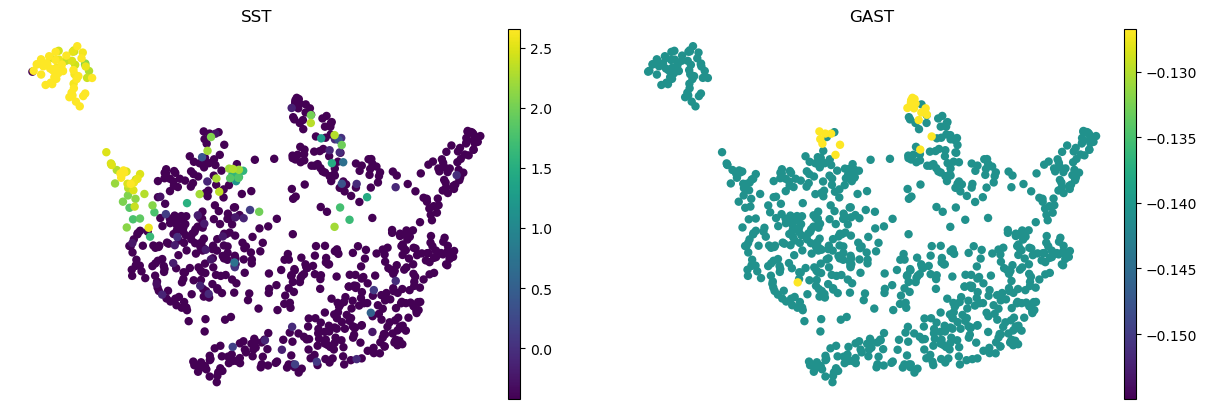

In [21]:
present = [g for g in More_Peptide_cell_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

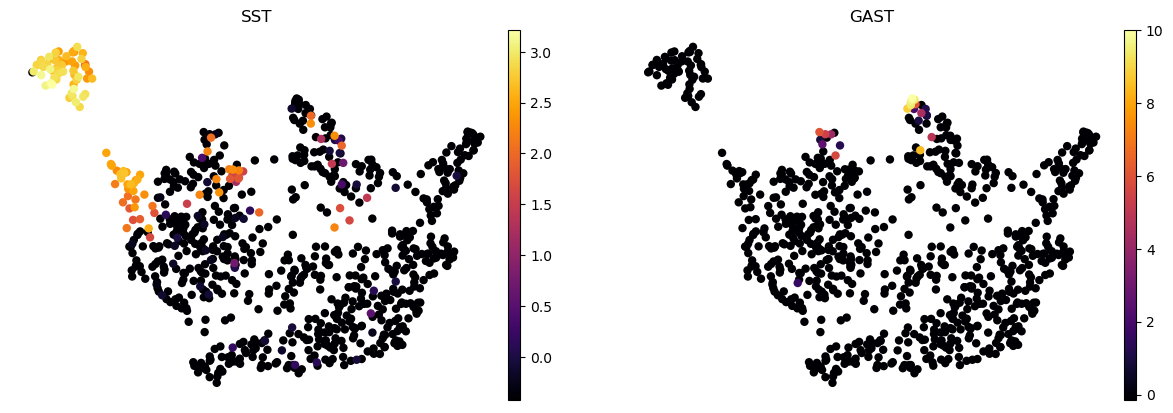

In [22]:

present = [g for g in More_Peptide_cell_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    cmap="inferno",         
    frameon=False
)

#### Plot Motilin

KeyError: 'Could not find key MLN in .var_names or .obs.columns.'

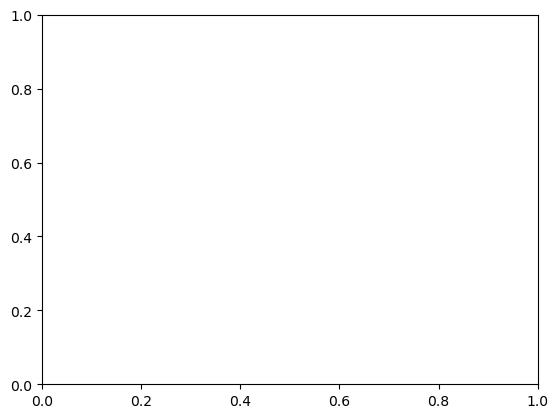

In [10]:
sc.pl.umap(
    adata,
    color="MLN",
    ncols=4,          # show expression from .raw if you froze it
    cmap="inferno",         
    frameon=False
)

#### Plot PAX4

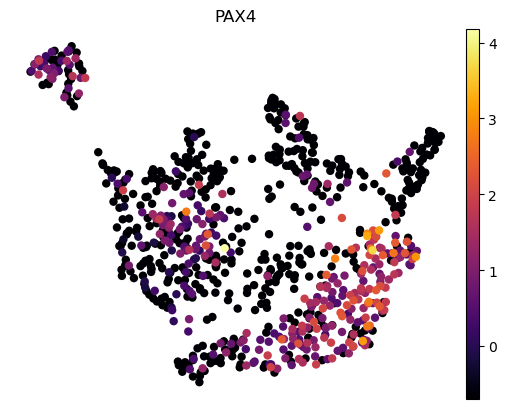

In [23]:
sc.pl.umap(
    adata,
    color="PAX4",
    ncols=4,          # show expression from .raw if you froze it
    cmap="inferno",         
    frameon=False
)

#### Plot PERCC1 & FAM181B

In [24]:
Cofactors = ["PERCC1", "FAM181B"]


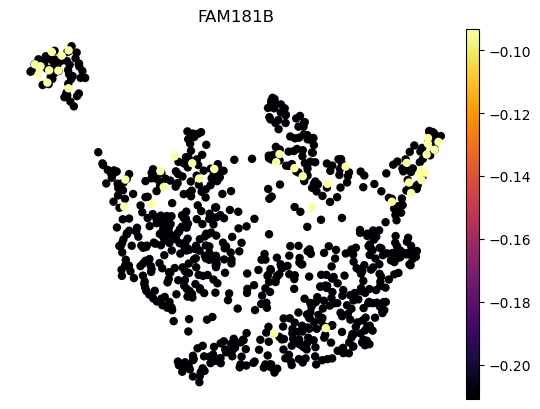

In [25]:
present = [g for g in Cofactors
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95", 
    cmap="inferno",         
    frameon=False
)

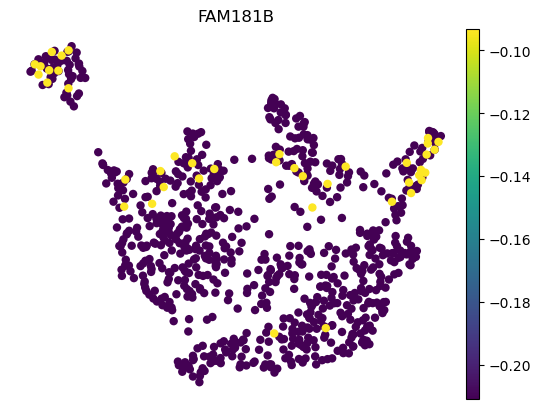

In [26]:
present = [g for g in Cofactors
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",       
    frameon=False
)

#### Define the two new metadata slots for our labels of the EECs

In [27]:
adata.obs['EEC_label'] = adata.obs['initial_cellassign_prediction']
adata.obs['granular_EEC_label'] = adata.obs['initial_cellassign_prediction']


#### Define our function for filtering on gene expression

In [28]:

def gene_expr_bool(adata, gene, threshold=0.0):
    """
    Return a boolean array (n_cells,) indicating which cells express `gene`
    above `threshold` in adata.X.
    If the gene is missing, returns all False.
    """
    if gene not in adata.var_names:
        print(f"Warning: {gene} not found in var_names; treating as not expressed.")
        return np.zeros(adata.n_obs, dtype=bool)
    
    sub = adata[:, gene]
    X = sub.X
    if issparse(X):
        X = X.toarray()
    X = np.ravel(X)
    return X > threshold

#### Define the categories


In [29]:
# if it's categorical, add the new category values you want to assign
if pd.api.types.is_categorical_dtype(adata.obs["EEC_label"]):
    adata.obs["EEC_label"] = adata.obs["EEC_label"].cat.add_categories(
        ["Peptide-hormone EECs", "Enterochromaffin cells"]
    )

/var/folders/gs/k55rgtm50g938k87mvcdclqr0000gq/T/ipykernel_30204/2036105681.py:2: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(adata.obs["EEC_label"]):


#### Define the Peptide hormones cells

In [30]:
arx_pos = gene_expr_bool(adata, "ARX")
mask_peptide_eec = arx_pos
# Cells that are positive for SST should be included in this criteria 

sst_pos = gene_expr_bool(adata, "SST")
mask_peptide_eec = arx_pos | sst_pos


adata.obs.loc[mask_peptide_eec, "EEC_label"] = "Peptide-hormone EECs"






#### Remove the categories from the originally copied CellAssign metadata column


In [31]:

adata.obs["EEC_label"] = adata.obs["EEC_label"].cat.remove_unused_categories()


#### Define enterochromaffin cells as the remaining cells, based on the abundance of CHGA

In [32]:
adata.obs["EEC_label"] = np.where(
    mask_peptide_eec,
    "Peptide-hormone EECs",
    "Enterochromaffin cells"
)


#### Plot the result

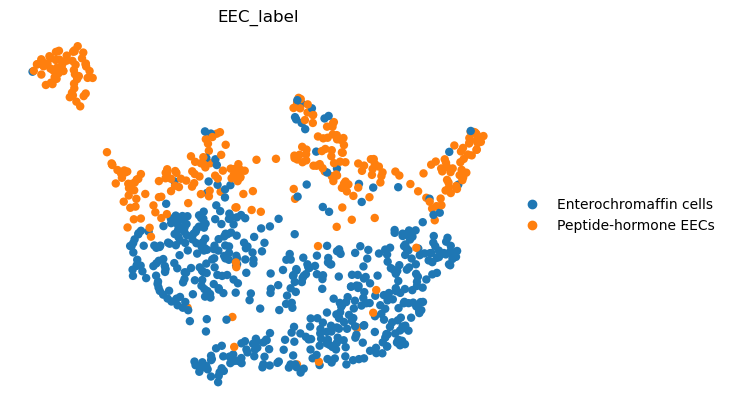

In [33]:
sc.pl.umap(
    adata,
    color="EEC_label",
    palette=sc.pl.palettes.default_20,  # or sc.pl.palettes.zeileis_28
    frameon=False
)

#### Repeat for the specific peptide cell types we've plotted

In [34]:
# if it's categorical, add the new category values you want to assign
if pd.api.types.is_categorical_dtype(adata.obs["granular_EEC_label"]):
    adata.obs["granular_EEC_label"] = adata.obs["granular_EEC_label"].cat.add_categories(
        ["X cells", "D cells", "I cells", "K cells", "Enterochromaffin cells"]
    )

/var/folders/gs/k55rgtm50g938k87mvcdclqr0000gq/T/ipykernel_30204/1377926025.py:2: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(adata.obs["granular_EEC_label"]):


#### Define the X cells

In [35]:
ghrl_pos = gene_expr_bool(adata, "GHRL")
mask_xcell_eec = ghrl_pos
# Cells that are positive for SST should be included in this criteria 
adata.obs.loc[mask_xcell_eec, "granular_EEC_label"] = "X cells"

#### Define the D cells

In [36]:
sst_pos = gene_expr_bool(adata, "SST")
mask_dcell_eec = sst_pos
# Cells that are positive for SST should be included in this criteria 
adata.obs.loc[mask_dcell_eec, "granular_EEC_label"] = "D cells"

#### Define the I cells

In [37]:
cck_pos = gene_expr_bool(adata, "CCK")
mask_icell_eec = cck_pos
# Cells that are positive for SST should be included in this criteria 
adata.obs.loc[mask_icell_eec, "granular_EEC_label"] = "I cells"

#### Define the K cells

In [38]:
gip_pos = gene_expr_bool(adata, "GIP")
mask_kcell_eec = gip_pos
# Cells that are positive for SST should be included in this criteria 
adata.obs.loc[mask_kcell_eec, "granular_EEC_label"] = "K cells"

#### Define the Enterochromaffin cells as the remaining cells

In [39]:

label_col = "granular_EEC_label"

# Ensure categorical + required categories exist
needed = ["X cells", "D cells", "I cells", "K cells", "Enterochromaffin cells"]
if label_col not in adata.obs:
    adata.obs[label_col] = pd.Categorical([None] * adata.n_obs, categories=needed)
else:
    if not pd.api.types.is_categorical_dtype(adata.obs[label_col]):
        adata.obs[label_col] = adata.obs[label_col].astype("category")
    adata.obs[label_col] = adata.obs[label_col].cat.add_categories(
        [c for c in needed if c not in adata.obs[label_col].cat.categories]
    )

# Anything not already labeled as X/D/I/K becomes Enterochromaffin
assigned = adata.obs[label_col].isin(["X cells", "D cells", "I cells", "K cells"])
adata.obs.loc[~assigned, label_col] = "Enterochromaffin cells"


/var/folders/gs/k55rgtm50g938k87mvcdclqr0000gq/T/ipykernel_30204/310932088.py:8: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if not pd.api.types.is_categorical_dtype(adata.obs[label_col]):


In [40]:
#### Drop the unused labels

In [41]:
adata.obs["granular_EEC_label"] = adata.obs["granular_EEC_label"].cat.remove_unused_categories()


#### Plot the result

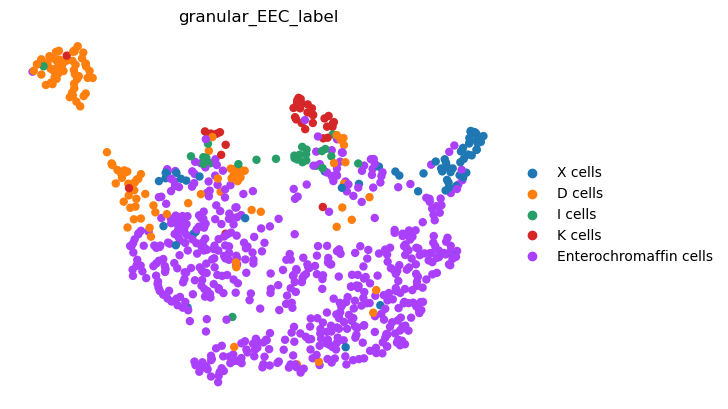

In [42]:
sc.pl.umap(
    adata,
    color="granular_EEC_label",
    palette=sc.pl.palettes.default_20,  # or sc.pl.palettes.zeileis_28
    frameon=False
)

In [43]:
adata

AnnData object with n_obs × n_vars = 819 × 3000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden', 'size_factor', 'initial_cellassign_prediction', 'leiden_subcluster', 'EEC_label', 'granular_EEC_label'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std', 'n_counts', 'highly_variable_rank', 'variances', 'variances_norm'
    uns: 'X_name', 'hvg', 'initial_cellassign_prediction_colors', 'leiden_colors', 'log1p', 'pca', 'neighbors', 'umap', 'leiden_subcluster', 'leiden_subcluster_colors', 'EEC_label_colors', 'granular_EEC_label_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [44]:
# --- Veres-style panel builder (Scanpy/AnnData) ---

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as patches
import matplotlib.patheffects as PathEffects
from collections import Counter, OrderedDict
from sklearn.neighbors import NearestNeighbors
from palettable.colorbrewer.qualitative import Set1_9, Paired_10, Set2_8

# -------------------- typography to match paper --------------------
def setup_matplotlib_params():
    from matplotlib import rcParams
    rcParams['font.family'] = 'sans-serif'
    rcParams['font.sans-serif'] = ['Helvetica Neue', 'Arial', 'DejaVu Sans']
    rcParams['axes.titlesize'] = 5
    rcParams['axes.labelsize']  = 5
    rcParams['xtick.labelsize'] = 5
    rcParams['ytick.labelsize'] = 5
    rcParams['axes.linewidth']  = 0.5
    rcParams['xtick.major.width'] = 0.5
    rcParams['ytick.major.width'] = 0.5
    rcParams['pdf.fonttype'] = 42  # editable text in Illustrator

setup_matplotlib_params()

# -------------------- core color registry (as in figure_vis.py) --------------------
def _col(x): return np.array(x)/255.

class CoreColors:
    def __init__(self):
        base = dict(zip(
            ['red','blue','green','purple','orange','brown','pink','grey'],
            Set1_9.colors
        ))
        for k,v in base.items(): setattr(self, k, _col(v))
        for name,c in zip(['blue','green','red','orange','purple'], Paired_10.colors[::2]):
            setattr(self, 'pale_'+name, _col(c))
        self.teal        = _col(Set2_8.colors[0])
        self.pale_brown  = _col([193,128,108])
        self.light_grey  = _col(Set2_8.colors[-1])
        self.dark_green  = _col([52,117,50])
        self.dark_grey   = np.array([0.5,0.5,0.5])

core_colors = CoreColors()

# -------------------- label params (you can fully customize) --------------------
def make_label_params(category_names, color_overrides=None):
    """
    Build a label->dict(color, short_label) map deterministically from the
    Veres palettes. Edit this to hard-code exact colors if desired.
    
    color_overrides : dict, optional
        e.g. {"Early EECs": [166, 86, 40]} to override specific label colors (RGB 0-255).
    """
    palette = (
        Set1_9.colors + Paired_10.colors[::2] + Set2_8.colors
    )
    lp = OrderedDict()
    for name, col in zip(category_names, palette):
        lp[name] = dict(color=_col(col), short_label=name)
    # Apply any per-label color overrides
    if color_overrides:
        for name, rgb in color_overrides.items():
            if name in lp:
                lp[name]['color'] = _col(rgb)
    return lp

# -------------------- identical logic: sort to put homogeneous neighborhoods on top --------------------
def prepare_for_scatter(X, labels, label_params):
    labels = np.asarray(labels)
    nbrs = NearestNeighbors(n_neighbors=10, algorithm='ball_tree').fit(X)
    knn = nbrs.kneighbors(X, return_distance=False)
    # fraction of neighbors with the same label; sort so dense/consistent are on top
    same = (labels[knn].T == labels[knn][:,0].T).mean(0)
    order = np.argsort(same)
    # map labels -> RGB
    colors = np.ones((len(labels),3))*0.5
    for k,v in label_params.items():
        colors[labels==k] = v['color']
    return X[order], colors[order]

# -------------------- the panel function (ports the notebook code) --------------------
def plot_veres_panel(
    adata,
    label_key,                 # e.g. "initial_cellassign_prediction_colors"
    stage_text=None,           # e.g. "D10_Lapa"
    ratio_order=None,          # list specifying order in pop-bar (optional)
    label_order=None,          # legend order (optional)
    color_overrides=None,      # dict of {label: [R,G,B]} to override specific colors
    save=None,                 # path to .pdf/.png
    dpi=600
):
    # coords & labels
    X = adata.obsm['X_umap']
    labels = adata.obs[label_key].astype(str).values
    cats = list(pd.unique(labels)) if label_order is None else label_order

    # label params (color + short label)
    lp = make_label_params(cats, color_overrides=color_overrides)

    # ===== panel sizing exactly like their notebook =====
    mm_per_inch = 25.4
    panel_size_in = ((89/2)/mm_per_inch, 25.4/mm_per_inch)  # (W, H)
    cell_pop_bar_h = 0.07
    heights = ((1 - cell_pop_bar_h)*panel_size_in[1], cell_pop_bar_h*panel_size_in[1])
    widths  = (panel_size_in[0] - heights[0], heights[0])  # legend column narrower than scatter

    fig = plt.figure(figsize=panel_size_in, dpi=dpi)
    gs  = gridspec.GridSpec(2, 2, fig, 0,0,1,1,
                            hspace=0, wspace=0,
                            width_ratios=widths, height_ratios=heights)

    # ===== left column: title + legend (with colored dots) =====
    ax = fig.add_subplot(gs[0,0], xticks=[], yticks=[], xlim=[0,1], ylim=[0,1], frameon=False)
    li = 1
    yl = lambda i: 1 - i/10.5
    xl_dot, xl_head, xl_text = 0.22, 0.30, 0.30

    # Title ("Stage X" in Veres; we show stage_text and n_cells)
    if stage_text is None:
        stage_text = ""
    ax.text(xl_head, yl(li) + 0.1, f"{stage_text}", va='center', fontsize=6, fontweight='extra bold', clip_on=False) ### changed line
    li += 1
    ax.text(xl_head, yl(li), f"({adata.n_obs:,} cells)", va='center', fontsize=5, clip_on=False)
    li += 1.5

    present = [c for c in (label_order or cats) if c in set(labels)]
    for lb in present:
        lb_txt = lp[lb]['short_label']
        ax.scatter(xl_dot, yl(li)+0.008, s=15, c=lp[lb]['color'].reshape(1,-1), clip_on=False)
        for line in str(lb_txt).splitlines():
            ax.text(xl_text, yl(li), line, va='center', fontsize=5, clip_on=False)
            li += 1

    # ===== right column: layered scatter (black -> white -> color), alpha as in notebook =====
    proj, rgb = prepare_for_scatter(X, labels, lp)
    ax = fig.add_subplot(gs[0,1], xticks=[], yticks=[], frameon=False, zorder=-1)
    ax.patch.set_visible(False)

    s_black, s_white, s_type = 4, 2, 1.5   # EXACT dot sizes used in the notebook
    ax.scatter(proj[:,0], proj[:,1], c='k', edgecolor='none', s=s_black, rasterized=True)
    ax.scatter(proj[:,0], proj[:,1], c='w', edgecolor='none', s=s_white, rasterized=True)
    ax.scatter(proj[:,0], proj[:,1], c=rgb, edgecolor='none', s=s_type, alpha=0.7, rasterized=True)

    # ===== bottom row: population ratio bar (with border rectangle and label) =====
    ax = fig.add_subplot(gs[1,0:2], xticks=[], yticks=[], xlim=[0,1], ylim=[0,1], frameon=False)

    counts = pd.Series(Counter(labels))
    fracs  = counts / counts.sum()
    rr = ratio_order or present  # if no ratio_order, follow legend order

    cumul = 0.0
    for lb in rr:
        if lb in fracs:
            w = float(fracs[lb])
            ax.add_patch(patches.Rectangle((0.30 + 0.68*cumul, 0.02), 0.68*w, 1.0,
                                           facecolor=lp[lb]['color'], edgecolor='none', clip_on=False))
            cumul += w

    ax.text(0.175, 0.5, 'Pop. ratios:', va='center', ha='center', fontsize=5, clip_on=False)
    ax.add_patch(patches.Rectangle((0.30, 0.02), 0.68, 1.0, facecolor='none', edgecolor='k', linewidth=0.5, clip_on=False))

    plt.tight_layout()
    if save:
        fig.savefig(save, dpi=dpi, transparent=True, bbox_inches='tight')
    return fig

/var/folders/gs/k55rgtm50g938k87mvcdclqr0000gq/T/ipykernel_2206/2008275420.py:156: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


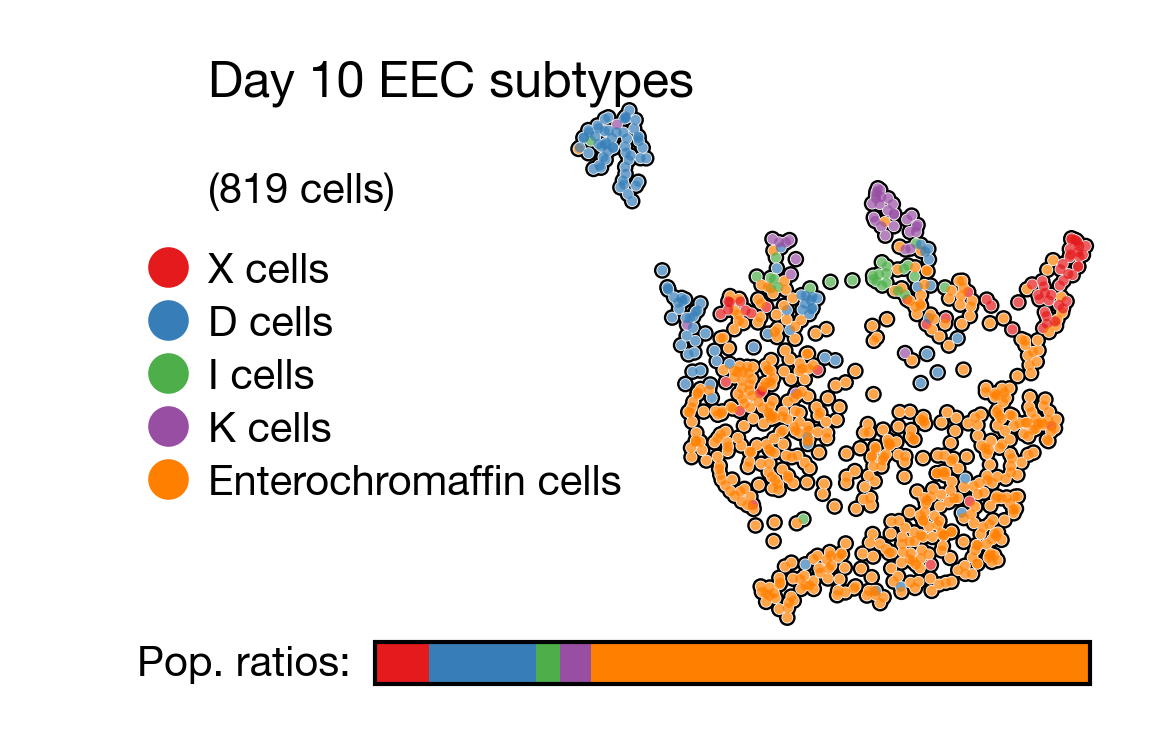

In [46]:
# Your schema
STAGE = "D10_Lapa"
LABEL_KEY = "granular_EEC_label"  # or your final label column

# Optional: lock display order (legend + pop-bar) to your preferred sequence
label_order = [
    "X cells", "D cells", "I cells",
    "K cells", "Enterochromaffin cells"
]
ratio_order = label_order  # can be different if you wish

# Subset if you had multiple stages; otherwise just pass your AnnData
fig = plot_veres_panel(
    adata, 
    label_key=LABEL_KEY,
    stage_text="Day 10 EEC subtypes",
    label_order=label_order,   # or None to use dataset order
    ratio_order=ratio_order,   # or None
    save="D10_EEC_subtypes.pdf"
)


#### Plotting our custom image for the simple EC peptide hormone bifurcation

/var/folders/gs/k55rgtm50g938k87mvcdclqr0000gq/T/ipykernel_26526/170953578.py:156: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


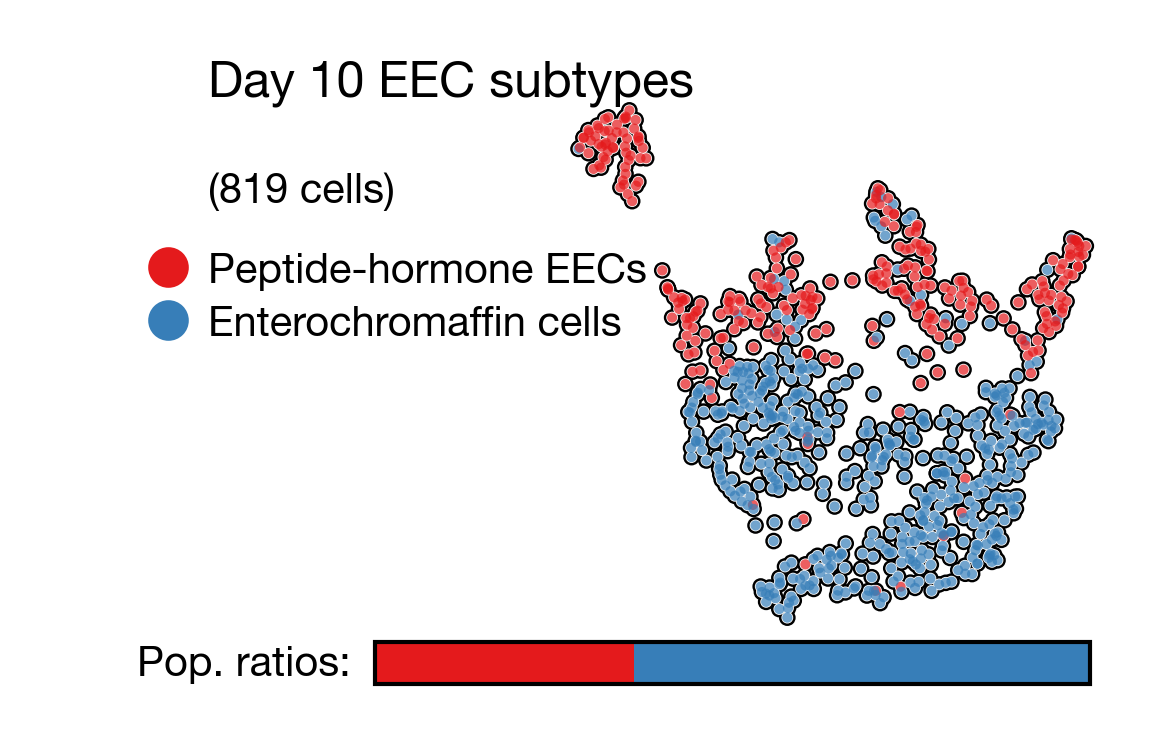

In [37]:
# Your schema
STAGE = "D10_Lapa"
LABEL_KEY = "EEC_label"  # or your final label column

# Optional: lock display order (legend + pop-bar) to your preferred sequence
label_order = [
    "Peptide-hormone EECs",
    "Enterochromaffin cells"
]
ratio_order = label_order  # can be different if you wish

# Subset if you had multiple stages; otherwise just pass your AnnData
fig = plot_veres_panel(
    adata, 
    label_key=LABEL_KEY,
    stage_text="Day 10 EEC subtypes",
    label_order=label_order,   # or None to use dataset order
    ratio_order=ratio_order,   # or None
    save="D10_simple_EEC_subtypes.pdf"
)


#### Save our new object

In [38]:
intermediate_directory = str(ANALYSIS_DIR / "manual_labelled_2")
sc.write(f'{intermediate_directory}/subclustered_EECs_egfDuod_D10_Lapa_DZ.h5ad', adata)

#### Continuing work to refine the peptide-hormone cells; and the enterochromaffin cells

In [45]:
adata.obs['granular_EEC_label_v2'] = adata.obs['granular_EEC_label']


In [46]:
# if it's categorical, add the new category values you want to assign
if pd.api.types.is_categorical_dtype(adata.obs["granular_EEC_label_v2"]):
    adata.obs["granular_EEC_label_v2"] = adata.obs["granular_EEC_label_v2"].cat.add_categories(
        ["ARX+ cells"]
    )

/var/folders/gs/k55rgtm50g938k87mvcdclqr0000gq/T/ipykernel_30204/2729569604.py:2: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(adata.obs["granular_EEC_label_v2"]):


#### Define the ARX+ cells

In [47]:
arx_pos = gene_expr_bool(adata, "ARX")
mask_peptide_cell_eec = arx_pos
# Cells that are positive for SST should be included in this criteria 
adata.obs.loc[mask_peptide_cell_eec, "granular_EEC_label_v2"] = "ARX+ cells"

#### Define the X cells

In [48]:
ghrl_pos = gene_expr_bool(adata, "GHRL")
mask_xcell_eec = ghrl_pos
# Cells that are positive for SST should be included in this criteria 
adata.obs.loc[mask_xcell_eec, "granular_EEC_label_v2"] = "X cells"

#### Define the D cells

In [49]:
sst_pos = gene_expr_bool(adata, "SST")
mask_dcell_eec = sst_pos
# Cells that are positive for SST should be included in this criteria 
adata.obs.loc[mask_dcell_eec, "granular_EEC_label_v2"] = "D cells"

#### Define the I cells

In [50]:
cck_pos = gene_expr_bool(adata, "CCK")
mask_icell_eec = cck_pos
# Cells that are positive for SST should be included in this criteria 
adata.obs.loc[mask_icell_eec, "granular_EEC_label_v2"] = "I cells"

#### Define the K cells

In [51]:
gip_pos = gene_expr_bool(adata, "GIP")
mask_kcell_eec = gip_pos
# Cells that are positive for SST should be included in this criteria 
adata.obs.loc[mask_kcell_eec, "granular_EEC_label_v2"] = "K cells"

#### Define the Enterochromaffin cells as the remaining cells

In [52]:

label_col = "granular_EEC_label_v2"

# Ensure categorical + required categories exist
needed = ["X cells", "D cells", "I cells", "K cells", "ARX+ cells", "Enterochromaffin cells"]
if label_col not in adata.obs:
    adata.obs[label_col] = pd.Categorical([None] * adata.n_obs, categories=needed)
else:
    if not pd.api.types.is_categorical_dtype(adata.obs[label_col]):
        adata.obs[label_col] = adata.obs[label_col].astype("category")
    adata.obs[label_col] = adata.obs[label_col].cat.add_categories(
        [c for c in needed if c not in adata.obs[label_col].cat.categories]
    )

# Anything not already labeled as X/D/I/K becomes Enterochromaffin
assigned = adata.obs[label_col].isin(["X cells", "D cells", "I cells", "K cells", "ARX+ cells"])
adata.obs.loc[~assigned, label_col] = "Enterochromaffin cells"


/var/folders/gs/k55rgtm50g938k87mvcdclqr0000gq/T/ipykernel_30204/3754234751.py:8: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if not pd.api.types.is_categorical_dtype(adata.obs[label_col]):


#### Drop the unused categories

In [53]:
adata.obs["granular_EEC_label_v2"] = adata.obs["granular_EEC_label_v2"].cat.remove_unused_categories()


In [54]:
#### Plot the results

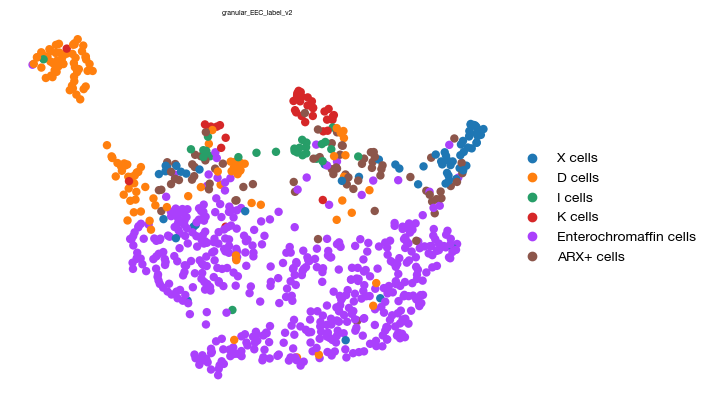

In [55]:
sc.pl.umap(
    adata,
    color="granular_EEC_label_v2",
    palette=sc.pl.palettes.default_20,  # or sc.pl.palettes.zeileis_28
    frameon=False
)

/var/folders/gs/k55rgtm50g938k87mvcdclqr0000gq/T/ipykernel_30204/4195793420.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


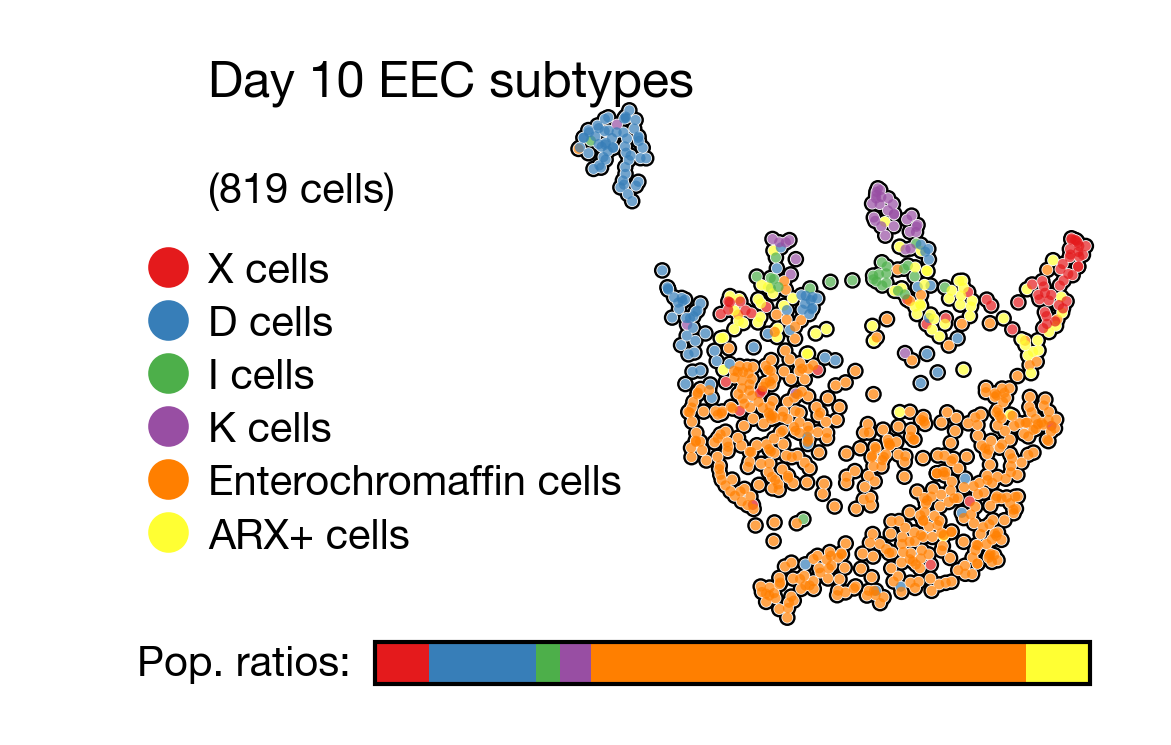

In [56]:
# Your schema
STAGE = "D10_Lapa"
LABEL_KEY = "granular_EEC_label_v2"  # or your final label column

# Optional: lock display order (legend + pop-bar) to your preferred sequence
label_order = [
    "X cells", "D cells", "I cells",
    "K cells", "Enterochromaffin cells", "ARX+ cells"
]
ratio_order = label_order  # can be different if you wish

# Subset if you had multiple stages; otherwise just pass your AnnData
fig = plot_veres_panel(
    adata, 
    label_key=LABEL_KEY,
    stage_text="Day 10 EEC subtypes",
    label_order=label_order,   # or None to use dataset order
    ratio_order=ratio_order,   # or None
    save="D10_EEC_subtypes_ARX.pdf"
)


#### We can improve on the ARX+ peptide hormone cells that don't clearly fit in a subtype, and are currently becoming Enterochromaffin by label as a result

#### Inspect our metadata for computation of distances and the nearest neighbour

In [57]:
adata

AnnData object with n_obs × n_vars = 819 × 3000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden', 'size_factor', 'initial_cellassign_prediction', 'leiden_subcluster', 'EEC_label', 'granular_EEC_label', 'granular_EEC_label_v2'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std', 'n_counts', 'highly_variable_rank', 'variances', 'variances_norm'
    uns: 'X_name', 'hvg', 'initial_cellassign_prediction_colors', 'leiden_colors', 'log1p', 'pca', 'neighbors', 'umap', 'leiden_subcluster', 'leiden_subcluster_colors', 'EEC_label_colors', 'granular_EEC_label_colors', 'granular_EEC_label_v2_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [58]:
adata.obsp['connectivities']

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 17076 stored elements and shape (819, 819)>

In [59]:
adata.obsp['distances']

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 11466 stored elements and shape (819, 819)>

#### Let's proceed with a graph based knn transfer of the ARX+ cells to one or another type of peptide hormone cells

#### Define strings for the metadata slot, and values to reassign, and holdout from the analysis respectively

In [60]:
label_key = "granular_EEC_label_v2"
default_label = "ARX+ cells"
holdout_label = "Enterochromaffin cells"

In [61]:
G = adata.obsp["connectivities"]

In [62]:
query_mask = adata.obs[label_key].eq(default_label).to_numpy()

In [63]:
reference_mask = adata.obs[label_key].ne(default_label)
if holdout_label is not None:
    reference_mask = reference_mask & adata.obs[label_key].ne(holdout_label)

reference_mask = reference_mask.to_numpy()

In [64]:
reference_labels = adata.obs.loc[reference_mask, label_key]
cats = reference_labels.cat.categories.tolist()

#### Graph based voting for default label, based on connectivities

In [65]:
import scipy.sparse as sp

G = adata.obsp["connectivities"].tocsr()

# one-hot labels over reference cells
Y_ref = sp.csr_matrix(
    (np.ones(reference_labels.shape[0]),
     (np.arange(reference_labels.shape[0]), reference_labels.cat.codes.to_numpy())),
    shape=(reference_labels.shape[0], len(cats))
)

G_qr = G[query_mask][:, reference_mask]
S = G_qr @ Y_ref

row_sums = np.asarray(S.sum(axis=1)).ravel()
row_sums[row_sums == 0] = 1.0
P = S.multiply(1 / row_sums[:, None])

P_dense = P.toarray()
g_idx = P_dense.argmax(axis=1)
g_conf = P_dense[np.arange(P_dense.shape[0]), g_idx]
g_pred = np.array([cats[i] for i in g_idx], dtype=object)

adata.obs.loc[adata.obs.index[query_mask], "pred_graph"] = g_pred
adata.obs.loc[adata.obs.index[query_mask], "conf_graph"] = g_conf


In [66]:
#### Check the shape of the matrices

In [67]:
assert G_qr.shape[0] == query_mask.sum()
assert G_qr.shape[1] == reference_mask.sum()
assert Y_ref.shape[0] == reference_mask.sum()


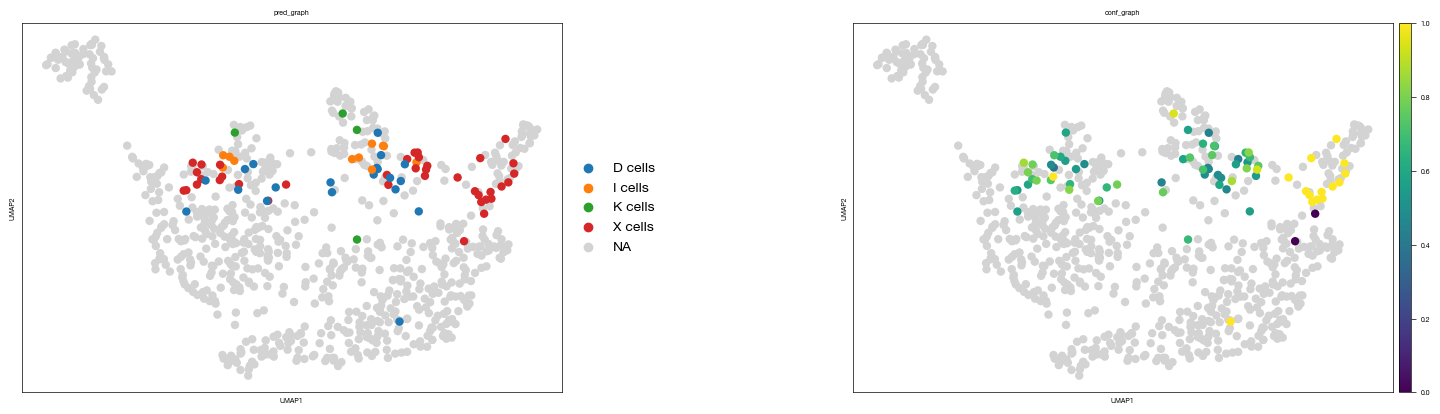

In [68]:
import scanpy as sc
sc.pl.umap(
    adata,
    color=["pred_graph", "conf_graph"],
    wspace=0.4
)


In [69]:
# Apply the kNN graph-based predictions back into granular_EEC_label_v2
# First convert to string to avoid categorical mismatch errors
adata.obs["granular_EEC_label_v2"] = adata.obs["granular_EEC_label_v2"].astype(str)

# Replace "ARX+ cells" with the predicted subtype from the graph voting
arx_mask = adata.obs["granular_EEC_label_v2"] == "ARX+ cells"
adata.obs.loc[arx_mask, "granular_EEC_label_v2"] = adata.obs.loc[arx_mask, "pred_graph"].astype(str)

# Convert back to categorical and clean up
adata.obs["granular_EEC_label_v2"] = adata.obs["granular_EEC_label_v2"].astype("category")
adata.obs["granular_EEC_label_v2"] = adata.obs["granular_EEC_label_v2"].cat.remove_unused_categories()

print(adata.obs["granular_EEC_label_v2"].value_counts())

granular_EEC_label_v2
Enterochromaffin cells    499
D cells                   142
X cells                   100
K cells                    40
I cells                    38
Name: count, dtype: int64


/var/folders/gs/k55rgtm50g938k87mvcdclqr0000gq/T/ipykernel_30204/4195793420.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


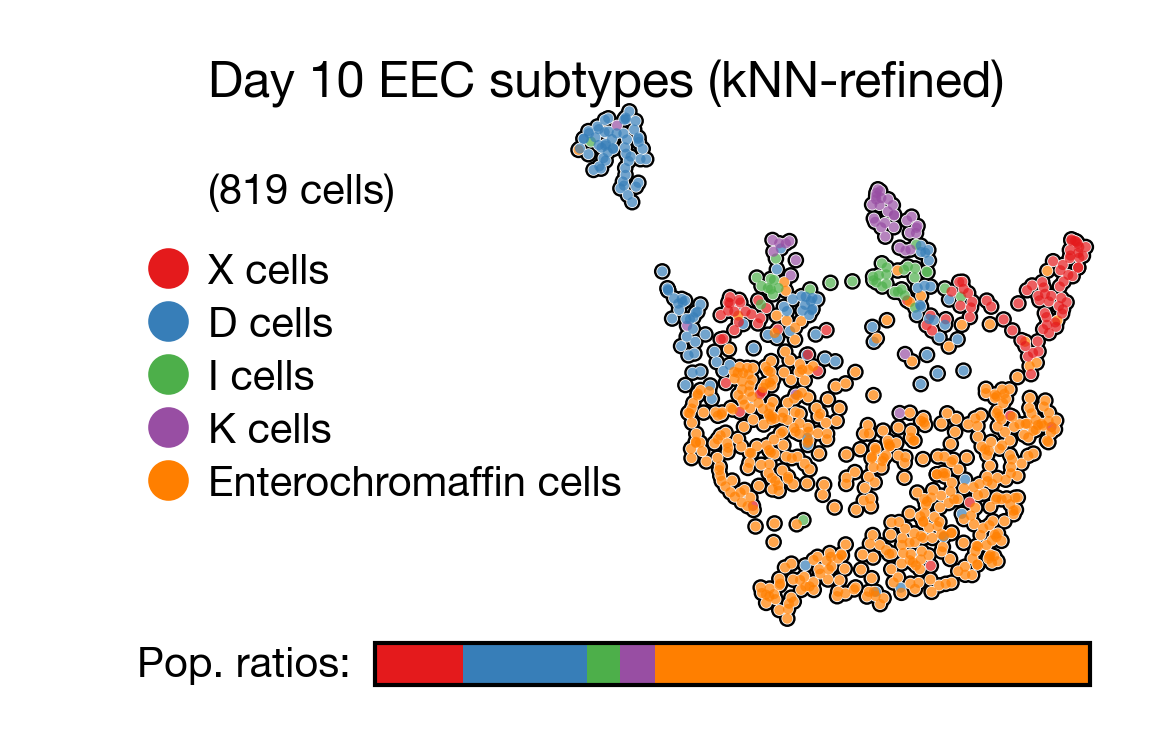

In [70]:
# Your schema
STAGE = "D10_Lapa"
LABEL_KEY = "granular_EEC_label_v2"

# Optional: lock display order (legend + pop-bar) to your preferred sequence
label_order = [
    "X cells", "D cells", "I cells",
    "K cells", "Enterochromaffin cells"
]
ratio_order = label_order

fig = plot_veres_panel(
    adata, 
    label_key=LABEL_KEY,
    stage_text="Day 10 EEC subtypes (kNN-refined)",
    label_order=label_order,
    ratio_order=ratio_order,
    save="D10_EEC_subtypes_kNN_refined.pdf"
)

#### That worked. Let's consider the 'Enterochromaffin cells' that express no TPH1, or LMX1A. These are in the bottom right hand corner of the UMAP

#### Let's plot some other potentially informative markers

In [71]:
sys.path.append(str(PROJECT_ROOT / "src"))

In [72]:
from src.markers import EEC_markers

In [73]:
Early_EEC_markers = EEC_markers["Early EECs"]

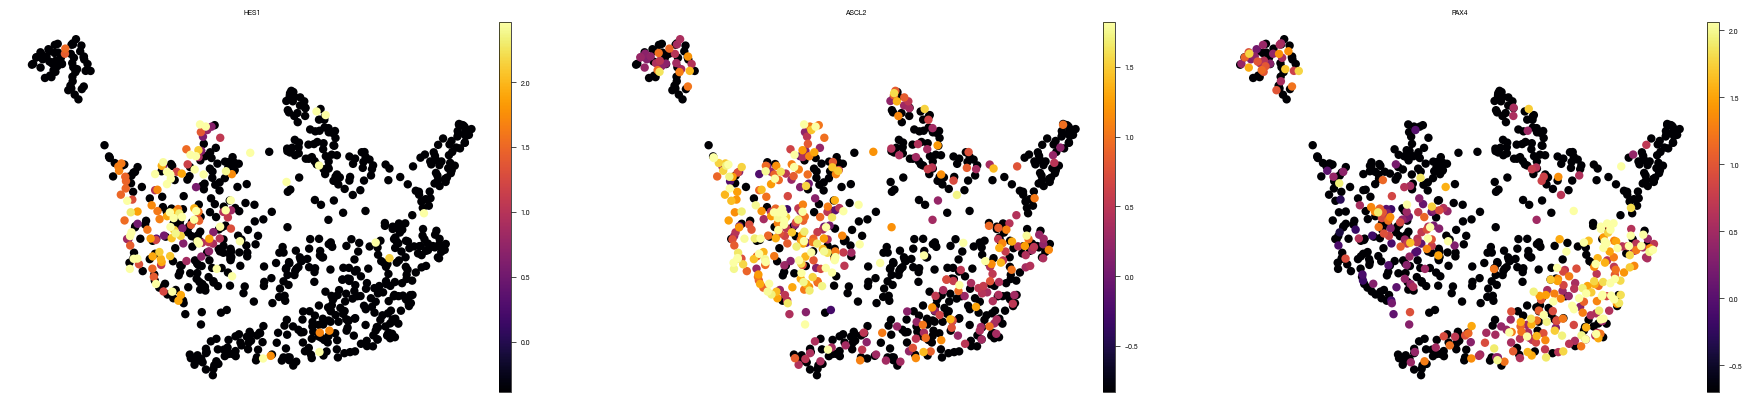

In [74]:
present = [g for g in Early_EEC_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95", 
    cmap="inferno",         
    frameon=False
)

In [75]:
T4_markers = EEC_markers["T4 cells"]

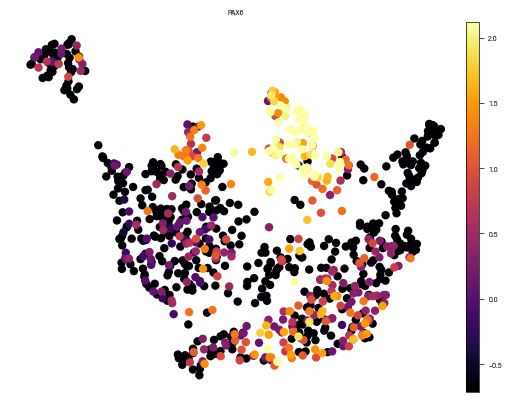

In [76]:
present = [g for g in T4_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95", 
    cmap="inferno",         
    frameon=False
)

In [77]:
pre_EEC_markers = EEC_markers["Pre EECs"]

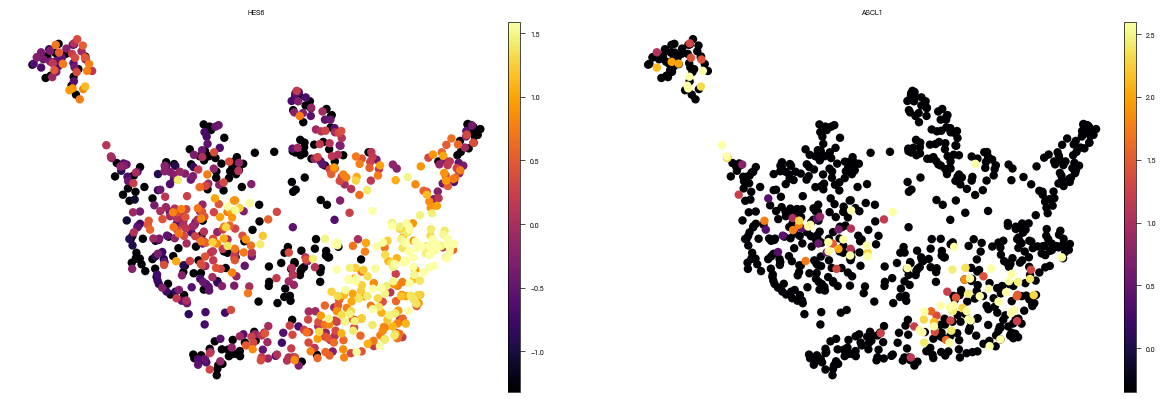

In [78]:
present = [g for g in pre_EEC_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95", 
    cmap="inferno",         
    frameon=False
)

In [79]:
#### NEUROG3, and the pre_EEC markers seem to mark these cells best, let's try labelling based on high NEUROG3

#### Define the label for our new category

In [80]:
new_label = "Early EECs"

#### Create v3 label: reassign Enterochromaffin cells with high NEUROG3 (z-scored > 1.5) to the new label

In [81]:
# Start from v2
adata.obs["granular_EEC_label_v3"] = adata.obs["granular_EEC_label_v2"].astype(str)

# Mask: Enterochromaffin cells with NEUROG3 z-scored expression > 1.5
ec_mask = adata.obs["granular_EEC_label_v3"] == "Enterochromaffin cells"
neurog3_high = gene_expr_bool(adata, "NEUROG3", threshold=1.5)
reassign_mask = ec_mask & neurog3_high

adata.obs.loc[reassign_mask, "granular_EEC_label_v3"] = new_label

# Convert to categorical
adata.obs["granular_EEC_label_v3"] = adata.obs["granular_EEC_label_v3"].astype("category")

print(f"Reassigned {reassign_mask.sum()} Enterochromaffin cells to '{new_label}'")
print()
print(adata.obs["granular_EEC_label_v3"].value_counts())

Reassigned 95 Enterochromaffin cells to 'Early EECs'

granular_EEC_label_v3
Enterochromaffin cells    404
D cells                   142
X cells                   100
Early EECs                 95
K cells                    40
I cells                    38
Name: count, dtype: int64


#### Plot the result

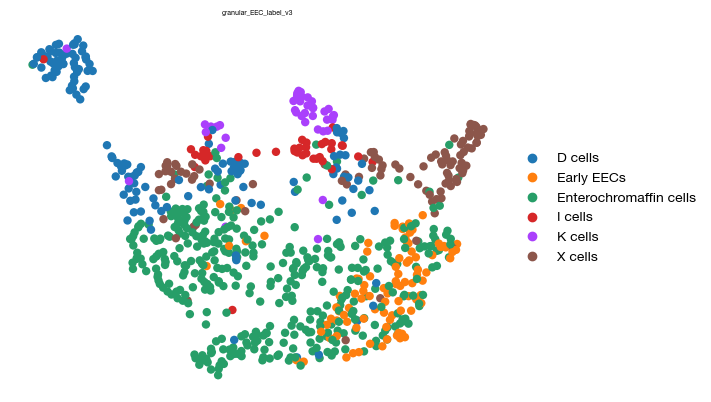

In [82]:
sc.pl.umap(
    adata,
    color="granular_EEC_label_v3",
    palette=sc.pl.palettes.default_20,
    frameon=False
)

/var/folders/gs/k55rgtm50g938k87mvcdclqr0000gq/T/ipykernel_30204/4195793420.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


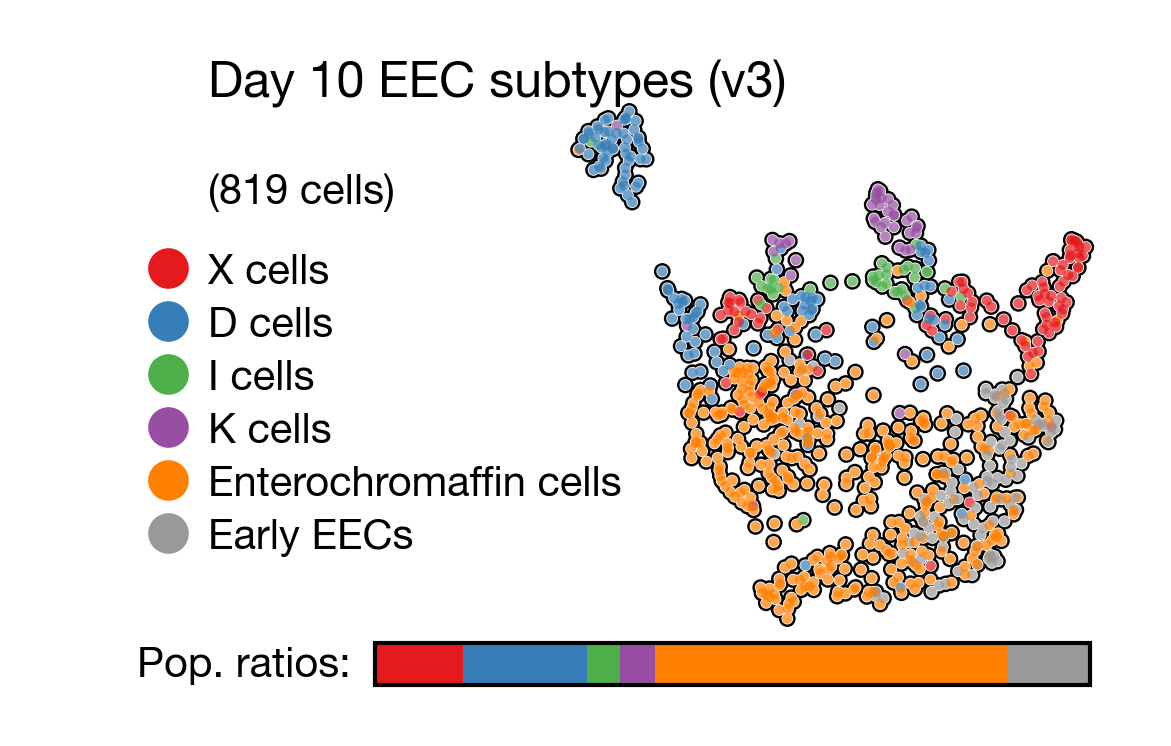

In [84]:
LABEL_KEY = "granular_EEC_label_v3"

label_order = [
    "X cells", "D cells", "I cells",
    "K cells", "Enterochromaffin cells", new_label
]
ratio_order = label_order

fig = plot_veres_panel(
    adata, 
    label_key=LABEL_KEY,
    stage_text="Day 10 EEC subtypes (v3)",
    label_order=label_order,
    ratio_order=ratio_order,
    color_overrides={new_label: [153, 153, 153]},  # brown; use [153, 153, 153] for grey [166, 86, 40] for brown
    save="D10_EEC_subtypes_v3.pdf"
)

In [ ]:
intermediate_directory = str(ANALYSIS_DIR / "manual_labelled_2")
sc.write(f'{intermediate_directory}/knn_EECs_egfDuod_D10_Lapa_DZ.h5ad', adata)

#### Create v4 label: reassign Early EECs using NEUROG3 z-scored > 1.0 (instead of 1.5)

In [ ]:
# Start from v2 (same base as v3, before the NEUROG3 threshold)
adata.obs["granular_EEC_label_v4"] = adata.obs["granular_EEC_label_v2"].astype(str)

# Mask: Enterochromaffin cells with NEUROG3 z-scored expression > 1.0
ec_mask = adata.obs["granular_EEC_label_v4"] == "Enterochromaffin cells"
neurog3_high = gene_expr_bool(adata, "NEUROG3", threshold=1.0)
reassign_mask = ec_mask & neurog3_high

adata.obs.loc[reassign_mask, "granular_EEC_label_v4"] = "Early EECs"

# Convert to categorical
adata.obs["granular_EEC_label_v4"] = adata.obs["granular_EEC_label_v4"].astype("category")

print(f"Reassigned {reassign_mask.sum()} Enterochromaffin cells to 'Early EECs' (threshold=1.0)")
print(f"(v3 used threshold=1.5 and reassigned 95)")
print()
print(adata.obs["granular_EEC_label_v4"].value_counts())

#### Plot the result (v4)

In [ ]:
sc.pl.umap(
    adata,
    color="granular_EEC_label_v4",
    palette=sc.pl.palettes.default_20,
    frameon=False,
    title="EEC subtypes v4 (NEUROG3 > 1.0)"
)

In [ ]:
LABEL_KEY = "granular_EEC_label_v4"

label_order = [
    "X cells", "D cells", "I cells",
    "K cells", "Enterochromaffin cells", "Early EECs"
]
ratio_order = label_order

fig = plot_veres_panel(
    adata, 
    label_key=LABEL_KEY,
    stage_text="Day 10 EEC subtypes (v4, NEUROG3>1.0)",
    label_order=label_order,
    ratio_order=ratio_order,
    color_overrides={"Early EECs": [153, 153, 153]},
    save="D10_EEC_subtypes_v4.pdf"
)

#### Save the v4 object

In [ ]:
intermediate_directory = str(ANALYSIS_DIR / "manual_labelled_2")
sc.write(f'{intermediate_directory}/knn_EECs_egfDuod_D10_Lapa_DZ.h5ad', adata)
print(f"Saved to {intermediate_directory}/knn_EECs_egfDuod_D10_Lapa_DZ.h5ad")

#### Create v5 labels: stricter hormone thresholds + kNN + EC connectivity reassignment + NEUROG3 Early EECs

Thresholds:
- GHRL > 4.0 → X cells (16 seeds)
- SST > 2.5 → D cells (54 seeds)
- CCK > 3.0 → I cells (17 seeds)
- GIP > 4.0 → K cells (19 seeds)
- NEUROG3 > 1.0 on Enterochromaffin → Early EECs (held out from kNN)
- ARX+ remainder → kNN transfer to nearest peptide subtype (2 passes)
- Enterochromaffin cells with >0.35 peptide connectivity → kNN transfer

In [ ]:
# Step 1: Start with all cells as Enterochromaffin, then apply strict hormone gates
adata.obs["granular_EEC_label_v5"] = "Enterochromaffin cells"

# Strict hormone thresholds
adata.obs.loc[gene_expr_bool(adata, "GHRL", threshold=4.0), "granular_EEC_label_v5"] = "X cells"
adata.obs.loc[gene_expr_bool(adata, "SST",  threshold=2.5), "granular_EEC_label_v5"] = "D cells"
adata.obs.loc[gene_expr_bool(adata, "CCK",  threshold=3.0), "granular_EEC_label_v5"] = "I cells"
adata.obs.loc[gene_expr_bool(adata, "GIP",  threshold=4.0), "granular_EEC_label_v5"] = "K cells"

# NEUROG3 > 1.0 → Early EECs (before kNN, so they're held out)
ec_mask = adata.obs["granular_EEC_label_v5"] == "Enterochromaffin cells"
neurog3_high = gene_expr_bool(adata, "NEUROG3", threshold=1.0)
adata.obs.loc[ec_mask & neurog3_high, "granular_EEC_label_v5"] = "Early EECs"

# ARX+ cells that weren't caught by strict gates or Early EECs
arx_pos = gene_expr_bool(adata, "ARX")
already_labelled = ~adata.obs["granular_EEC_label_v5"].isin(["Enterochromaffin cells"])
adata.obs.loc[arx_pos & ~already_labelled, "granular_EEC_label_v5"] = "ARX+ cells"

print("After strict gates + Early EECs + ARX+:")
print(adata.obs["granular_EEC_label_v5"].value_counts())
print()

In [ ]:
# Step 2: kNN transfer for ARX+ cells → nearest peptide subtype (2 passes)
# Hold out both Enterochromaffin and Early EECs from the reference
import scipy.sparse as sp

label_col = "granular_EEC_label_v5"
G = adata.obsp["connectivities"].tocsr()

for pass_n in [1, 2]:
    adata.obs[label_col] = adata.obs[label_col].astype("category")
    query_mask = (adata.obs[label_col] == "ARX+ cells").to_numpy()
    if query_mask.sum() == 0:
        print(f"Pass {pass_n}: no ARX+ cells remaining")
        break
    reference_mask = adata.obs[label_col].isin(["X cells", "D cells", "I cells", "K cells"]).to_numpy()
    reference_labels = adata.obs.loc[reference_mask, label_col]
    cats = reference_labels.cat.categories.tolist()

    Y_ref = sp.csr_matrix(
        (np.ones(reference_labels.shape[0]),
         (np.arange(reference_labels.shape[0]), reference_labels.cat.codes.to_numpy())),
        shape=(reference_labels.shape[0], len(cats))
    )
    G_qr = G[query_mask][:, reference_mask]
    S = G_qr @ Y_ref
    row_sums = np.asarray(S.sum(axis=1)).ravel()
    row_sums[row_sums == 0] = 1.0
    P_dense = (S.multiply(1 / row_sums[:, None])).toarray()
    g_idx = P_dense.argmax(axis=1)
    g_conf = P_dense[np.arange(P_dense.shape[0]), g_idx]
    g_pred = np.array([cats[i] for i in g_idx], dtype=object)

    adata.obs[label_col] = adata.obs[label_col].astype(str)
    has_conn = np.asarray((G_qr > 0).sum(axis=1)).ravel() > 0
    query_idx = adata.obs.index[query_mask]
    adata.obs.loc[query_idx[has_conn], label_col] = g_pred[has_conn]

    n_transferred = has_conn.sum()
    n_remaining = (~has_conn).sum()
    conf_str = f"mean conf: {g_conf[has_conn].mean():.3f}" if n_transferred > 0 else ""
    print(f"Pass {pass_n}: transferred {n_transferred}, remaining {n_remaining} {conf_str}")

# Fold any remaining ARX+ into Enterochromaffin
adata.obs.loc[adata.obs[label_col] == "ARX+ cells", label_col] = "Enterochromaffin cells"

print()
print("After kNN transfer:")
print(adata.obs[label_col].value_counts())
print()

In [ ]:
# Step 3: Reassign Enterochromaffin cells with >0.35 peptide connectivity via kNN
labels = adata.obs[label_col].values
ec_mask = np.array(labels == "Enterochromaffin cells")
peptide_mask = np.isin(labels, ["X cells", "D cells", "I cells", "K cells"])

ec_indices = np.where(ec_mask)[0]
pep_frac = np.zeros(adata.n_obs)
for i in ec_indices:
    row = G[i].toarray().ravel()
    total = row.sum()
    if total > 0:
        pep_frac[i] = row[peptide_mask].sum() / total

ec_reassign = ec_mask & (pep_frac > 0.35)
print(f"EC cells with peptide connectivity > 0.35: {ec_reassign.sum()}")

adata.obs.loc[ec_reassign, label_col] = "EC_candidate"
adata.obs[label_col] = adata.obs[label_col].astype("category")

query_mask = (adata.obs[label_col] == "EC_candidate").to_numpy()
reference_mask = adata.obs[label_col].isin(["X cells", "D cells", "I cells", "K cells"]).to_numpy()
reference_labels = adata.obs.loc[reference_mask, label_col]
cats = reference_labels.cat.categories.tolist()

Y_ref = sp.csr_matrix(
    (np.ones(reference_labels.shape[0]),
     (np.arange(reference_labels.shape[0]), reference_labels.cat.codes.to_numpy())),
    shape=(reference_labels.shape[0], len(cats))
)
G_qr = G[query_mask][:, reference_mask]
S = G_qr @ Y_ref
row_sums = np.asarray(S.sum(axis=1)).ravel()
row_sums[row_sums == 0] = 1.0
P_dense = (S.multiply(1 / row_sums[:, None])).toarray()
g_idx = P_dense.argmax(axis=1)
g_conf = P_dense[np.arange(P_dense.shape[0]), g_idx]
g_pred = np.array([cats[i] for i in g_idx], dtype=object)

adata.obs[label_col] = adata.obs[label_col].astype(str)
has_conn = np.asarray((G_qr > 0).sum(axis=1)).ravel() > 0
query_idx = adata.obs.index[query_mask]
adata.obs.loc[query_idx[has_conn], label_col] = g_pred[has_conn]
adata.obs.loc[query_idx[~has_conn], label_col] = "Enterochromaffin cells"
adata.obs[label_col] = adata.obs[label_col].replace("EC_candidate", "Enterochromaffin cells")
adata.obs[label_col] = adata.obs[label_col].astype("category")

print(f"Transferred {has_conn.sum()} EC cells (mean conf: {g_conf[has_conn].mean():.3f})")
print()
print("EC candidate destinations:")
print(pd.Series(g_pred[has_conn]).value_counts())
print()
print("Final v5 labels:")
print(adata.obs[label_col].value_counts())

#### Plot v5 results

In [ ]:
sc.pl.umap(
    adata,
    color="granular_EEC_label_v5",
    palette=sc.pl.palettes.default_20,
    frameon=False,
    title="EEC subtypes v5 (strict gates + kNN)"
)

In [ ]:
LABEL_KEY = "granular_EEC_label_v5"

label_order = [
    "X cells", "D cells", "I cells",
    "K cells", "Enterochromaffin cells", "Early EECs"
]
ratio_order = label_order

fig = plot_veres_panel(
    adata, 
    label_key=LABEL_KEY,
    stage_text="Day 10 EEC subtypes (v5)",
    label_order=label_order,
    ratio_order=ratio_order,
    color_overrides={"Early EECs": [153, 153, 153]},
)

#### Save v5 object

In [ ]:
intermediate_directory = str(ANALYSIS_DIR / "manual_labelled_2")
sc.write(f'{intermediate_directory}/knn_EECs_egfDuod_D10_Lapa_DZ.h5ad', adata)
print(f"Saved to {intermediate_directory}/knn_EECs_egfDuod_D10_Lapa_DZ.h5ad")